# Task 2 — SQL for Data Extraction
## Python + SQL Integration Notebook

**ApexPlanet Data Analytics Internship**

This notebook is the Python half of Task 2. The SQL itself lives in the
`sql/` folder as runnable `.sql` files; here we drive the same database from
Python using **SQLAlchemy** and **`pandas.read_sql()`**, which is how SQL is
normally consumed inside a data pipeline or a report.

**What this notebook covers**

1. Connecting to MySQL with SQLAlchemy
2. Inspecting the database that `scripts/db_utils.py --load` created
3. Using `pandas.read_sql()` to turn query results straight into DataFrames
4. Parameterised queries, the safe alternative to string concatenation
5. Answering the 10 business questions from the brief
6. Reusing SQL views and exporting results

**Dataset:** the cleaned Sample Superstore dataset from Task 1
(`data/superstore_cleaned.csv`) — 9,994 order lines, Jan 2014 to Dec 2017.

> **Prerequisites:** MySQL running locally, `.env` filled in, and the database
> built once with `python scripts/db_utils.py --load`.

## 1. Setup

First we locate the project root and import the project's own database
utility module, `scripts/db_utils.py`. Reusing one module everywhere is the
"reusable database utility script" deliverable — the notebook, the CLI and
any future script all connect the same way.

In [1]:
import sys
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk upwards until we find the folder containing scripts/db_utils.py."""
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "db_utils.py").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root (scripts/db_utils.py)")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

from db_utils import TABLE_NAME, get_engine, get_settings, run_query

settings = get_settings()
print(f"Host      : {settings['host']}:{settings['port']}")
print(f"User      : {settings['user']}")
print(f"Database  : {settings['database']}")
print(f"Project   : {PROJECT_ROOT}")

Host      : 127.0.0.1:3306
User      : root
Database  : apexplanet
Project   : C:\Users\juhip\OneDrive\Desktop\python folder\apexplanet-data-analytics\apexplanet-data-analytics-task-2


### 1.1 Checking the connection with SQLAlchemy

`get_engine()` returns a SQLAlchemy engine, which is a connection pool. The
password is read from `.env` and never hard-coded in the notebook.

In [2]:
from sqlalchemy import text

with get_engine().connect() as conn:
    version, current_db = conn.execute(text("SELECT VERSION(), DATABASE()")).one()

print("MySQL version :", version)
print("Active schema :", current_db)

MySQL version : 8.0.46
Active schema : apexplanet


## 2. What is in the database?

`db_utils.py --load` created one table (`superstore`) and five views. Let's
list them with their row counts, straight from `information_schema`.

In [3]:
inventory = run_query("""
    SELECT table_name AS name, table_type AS type
    FROM information_schema.tables
    WHERE table_schema = DATABASE()
    ORDER BY table_type, table_name
""")

inventory["rows"] = [
    run_query(f"SELECT COUNT(*) AS n FROM `{name}`").iloc[0, 0]
    for name in inventory["name"]
]

inventory

,name,type,rows
0,superstore,BASE TABLE,9994
1,vw_category_performance,VIEW,17
2,vw_customer_summary,VIEW,793
3,vw_monthly_sales,VIEW,48
4,vw_product_performance,VIEW,1894
5,vw_region_performance,VIEW,4


### 2.1 The columns of the `superstore` table

The CSV headers were converted to snake_case (`Sub-Category` becomes
`sub_category`) and given explicit types in `sql/01_schema.sql`, rather than
letting pandas guess them.

In [4]:
columns = run_query(f"SHOW COLUMNS FROM {TABLE_NAME}")
columns

,Field,Type,Null,Key,Default,Extra
0,row_id,int,NO,PRI,NaN,
1,order_id,varchar(20),NO,,NaN,
2,order_date,date,NO,MUL,NaN,
3,ship_date,date,NO,,NaN,
4,ship_mode,varchar(30),YES,,NaN,
5,customer_id,varchar(20),YES,MUL,NaN,
6,customer_name,varchar(60),YES,,NaN,
7,segment,varchar(20),YES,,NaN,
8,country,varchar(40),YES,,NaN,
9,city,varchar(60),YES,,NaN,


### 2.2 A quick profile of the data

In [5]:
profile = run_query(f"""
    SELECT
        MIN(order_date)             AS first_order,
        MAX(order_date)             AS last_order,
        COUNT(*)                    AS line_items,
        COUNT(DISTINCT order_id)    AS orders,
        COUNT(DISTINCT customer_id) AS customers,
        COUNT(DISTINCT product_id)  AS products,
        ROUND(SUM(sales), 2)        AS total_sales,
        ROUND(SUM(profit), 2)       AS total_profit
    FROM {TABLE_NAME}
""")
profile

,first_order,last_order,line_items,orders,customers,products,total_sales,total_profit
0,2014-01-03,2017-12-30,9994,5009,793,1862,"2,297,200.86","286,397.02"


## 3. `pandas.read_sql()` — SQL straight into a DataFrame

`read_sql()` runs a query and returns a DataFrame, so there is no manual
cursor handling. You can pass a plain SQL string, or a `text()` clause when
you need bound parameters.

In [6]:
query = f"""
SELECT
    category,
    ROUND(SUM(sales), 2)  AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM {TABLE_NAME}
GROUP BY category
ORDER BY total_sales DESC
"""

category_df = pd.read_sql(query, get_engine())
category_df

,category,total_sales,total_profit
0,Technology,"836,154.03","145,454.95"
1,Furniture,"741,999.80","18,451.27"
2,Office Supplies,"719,047.03","122,490.80"


### 3.1 Why the engine is cached

`get_engine()` memoises one engine per database, so calling it repeatedly in a
notebook does not open a new pool each time:

```python
_ENGINES = {}

def get_engine(database=None):
    ...
    if cache_key not in _ENGINES:
        _ENGINES[cache_key] = create_engine(url, pool_pre_ping=True)
    return _ENGINES[cache_key]
```

## 4. Parameterised queries

Never build SQL with f-strings or `+` when the value comes from a user or a
variable — that is how SQL injection happens. Use **bound parameters**
instead; SQLAlchemy passes them safely to the driver.

In [7]:
stmt = text("""
    SELECT order_id, order_date, customer_name, product_name, ROUND(sales, 2) AS sales
    FROM superstore
    WHERE region = :region
      AND sales  > :min_sales
    ORDER BY sales DESC
    LIMIT 5
""")

top_west = pd.read_sql(stmt, get_engine(), params={"region": "West", "min_sales": 4000})
top_west

,order_id,order_date,customer_name,product_name,sales
0,CA-2017-140151,2017-03-23,Raymond Buch,Canon imageCLASS 2200 Advanced Copier,"13,999.96"
1,CA-2014-143917,2014-07-25,Ken Lonsdale,High Speed Automatic Electric Letter Opener,"8,187.65"
2,CA-2017-135909,2017-10-13,Jane Waco,Fellowes PB500 Electric Punch Plastic Comb Bin...,"5,083.96"
3,CA-2016-136301,2016-03-13,Edward Hooks,High Speed Automatic Electric Letter Opener,"4,912.59"
4,CA-2017-149881,2017-04-01,Nick Crebassa,Cubify CubeX 3D Printer Double Head Print,"4,799.98"


In [8]:
# The same statement with different parameters - no SQL text changed.
for region in ["East", "Central", "South"]:
    df = pd.read_sql(stmt, get_engine(), params={"region": region, "min_sales": 4000})
    if len(df):
        print(f"{region:<8} -> {len(df)} qualifying line(s), top sale = ${df['sales'].max():,.2f}")
    else:
        print(f"{region:<8} -> none")

East     -> 5 qualifying line(s), top sale = $11,199.97
Central  -> 5 qualifying line(s), top sale = $17,499.95
South    -> 5 qualifying line(s), top sale = $22,638.48


## 5. The 10 business questions

Each question below is answered with SQL executed through `pandas.read_sql()`.
The canonical copies of these queries live in
`sql/04_business_questions.sql`, together with the written interpretation.

### Q1. Which are the top 5 products by total sales?

**Answer:** the Canon imageCLASS 2200 Advanced Copier leads at $61,599.82,
about 2.2x the runner-up. Technology equipment dominates the top 5 — high
ticket items, not high volume ones, carry revenue here.

In [9]:
pd.read_sql(f"""
    SELECT
        product_name,
        category,
        ROUND(SUM(sales), 2) AS total_sales,
        SUM(quantity)        AS units_sold
    FROM {TABLE_NAME}
    GROUP BY product_name, category
    ORDER BY total_sales DESC
    LIMIT 5
""", get_engine())

,product_name,category,total_sales,units_sold
0,Canon imageCLASS 2200 Advanced Copier,Technology,"61,599.82",20.00
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,"27,453.38",31.00
2,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48",6.00
3,HON 5400 Series Task Chairs for Big and Tall,Furniture,"21,870.58",39.00
4,GBC DocuBind TL300 Electric Binding System,Office Supplies,"19,823.48",37.00


### Q2. What is the monthly sales trend, and how fast is it growing?

`LAG()` compares each month with the one before it.

In [10]:
monthly_trend = pd.read_sql(f"""
    WITH monthly AS (
        SELECT month, SUM(sales) AS total_sales
        FROM {TABLE_NAME}
        GROUP BY month
    )
    SELECT
        month,
        ROUND(total_sales, 2) AS total_sales,
        ROUND(total_sales - LAG(total_sales) OVER (ORDER BY month), 2) AS mom_change,
        ROUND(
            100 * (total_sales - LAG(total_sales) OVER (ORDER BY month))
            / NULLIF(LAG(total_sales) OVER (ORDER BY month), 0), 2
        ) AS mom_growth_pct
    FROM monthly
    ORDER BY month
""", get_engine())

monthly_trend.tail(12)

,month,total_sales,mom_change,mom_growth_pct
36,2017-01,"43,971.37","-53,027.67",-54.67
37,2017-02,"20,301.13","-23,670.24",-53.83
38,2017-03,"58,872.35","38,571.22",190.00
39,2017-04,"36,521.54","-22,350.82",-37.96
40,2017-05,"44,261.11","7,739.57",21.19
41,2017-06,"52,981.73","8,720.62",19.70
42,2017-07,"45,264.42","-7,717.31",-14.57
43,2017-08,"63,120.89","17,856.47",39.45
44,2017-09,"87,866.65","24,745.76",39.20
45,2017-10,"77,776.92","-10,089.73",-11.48


**Answer:** sales run from $14,236.90 (Jan 2014) to a peak of $118,447.83
(Nov 2017). The pattern is seasonal rather than a smooth ramp: the biggest
months are Nov 2017, Dec 2016, Sep 2017 and Dec 2017, so September and the Q4
holiday season drive the peaks.

#### Plotting the result — DataFrames come out chart-ready

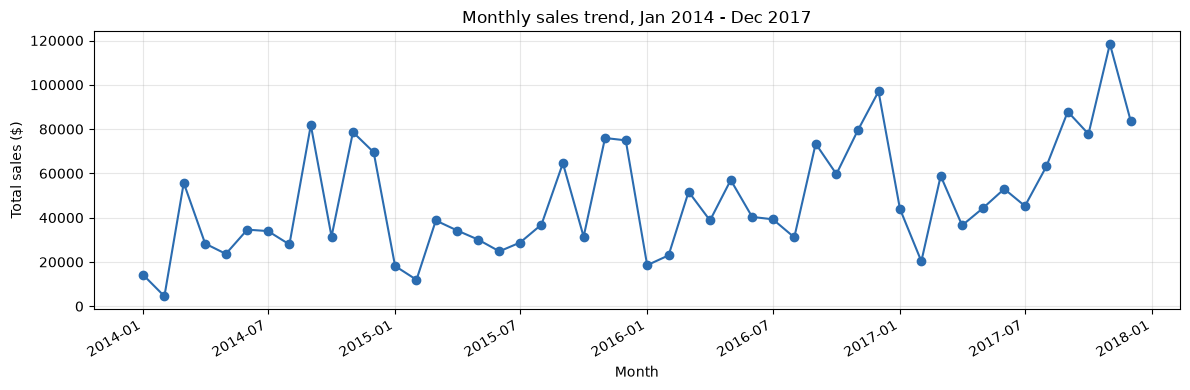

In [11]:
import matplotlib.pyplot as plt

trend = monthly_trend.copy()
trend["month"] = pd.to_datetime(trend["month"])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trend["month"], trend["total_sales"], marker="o", linewidth=1.5, color="#2b6cb0")
ax.set_title("Monthly sales trend, Jan 2014 - Dec 2017")
ax.set_xlabel("Month")
ax.set_ylabel("Total sales ($)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()

chart_dir = PROJECT_ROOT / "reports" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(chart_dir / "task2_monthly_sales_trend.png", dpi=120)
plt.show()

### Q3. How can customers be segmented by their total spend?

**Answer:** 117 customers (14.8%) are High Value and account for 39.70% of
sales; the 353 Low Value customers, the largest group, bring in only 15.81%.
A High Value customer spends 7.6x a Low Value one.

In [12]:
pd.read_sql(f"""
    WITH customer_spend AS (
        SELECT customer_id, customer_name, SUM(sales) AS total_sales
        FROM {TABLE_NAME}
        GROUP BY customer_id, customer_name
    )
    SELECT
        CASE
            WHEN total_sales >= 5000 THEN 'High Value'
            WHEN total_sales >= 2000 THEN 'Medium Value'
            ELSE 'Low Value'
        END                        AS spend_segment,
        COUNT(*)                   AS customers,
        ROUND(SUM(total_sales), 2) AS segment_sales,
        ROUND(AVG(total_sales), 2) AS avg_spend
    FROM customer_spend
    GROUP BY spend_segment
    ORDER BY segment_sales DESC
""", get_engine())

,spend_segment,customers,segment_sales,avg_spend
0,Medium Value,323,"1,022,071.07","3,164.31"
1,High Value,117,"911,958.27","7,794.52"
2,Low Value,353,"363,171.52","1,028.81"


### Q4. Who are the top 10 customers by sales, and are they profitable?

**Answer:** Sean Miller is number 1 by sales ($25,043.05) but **loses**
$1,980.74 — revenue without profit is a trap. Margins across the top 10 range
from -7.9% to +47.1%.

In [13]:
pd.read_sql(f"""
    SELECT
        customer_name,
        COUNT(DISTINCT order_id)                            AS orders,
        ROUND(SUM(sales), 2)                                AS total_sales,
        ROUND(SUM(profit), 2)                               AS total_profit,
        ROUND(100 * SUM(profit) / NULLIF(SUM(sales), 0), 2) AS profit_margin_pct
    FROM {TABLE_NAME}
    GROUP BY customer_id, customer_name
    ORDER BY total_sales DESC
    LIMIT 10
""", get_engine())

,customer_name,orders,total_sales,total_profit,profit_margin_pct
0,Sean Miller,5,"25,043.05","-1,980.74",-7.91
1,Tamara Chand,5,"19,052.22","8,981.32",47.14
2,Raymond Buch,6,"15,117.34","6,976.10",46.15
3,Tom Ashbrook,4,"14,595.62","4,703.79",32.23
4,Adrian Barton,10,"14,473.57","5,444.81",37.62
5,Ken Lonsdale,12,"14,175.23",806.86,5.69
6,Sanjit Chand,9,"14,142.33","5,757.41",40.71
7,Hunter Lopez,6,"12,873.30","5,622.43",43.68
8,Sanjit Engle,11,"12,209.44","2,650.68",21.71
9,Christopher Conant,5,"12,129.07","2,177.05",17.95


### Q5. Which categories and sub-categories drive sales and profit?

**Answer:** Technology is the most profitable category ($145,454.95, a 17.40%
margin). Furniture is the problem — $741,999.80 of sales yields only
$18,451.27 (2.49%) because Tables, Bookcases and Supplies all run at a loss.

In [14]:
pd.read_sql(f"""
    SELECT
        category,
        sub_category,
        ROUND(SUM(sales), 2)                                AS total_sales,
        ROUND(SUM(profit), 2)                               AS total_profit,
        ROUND(100 * SUM(profit) / NULLIF(SUM(sales), 0), 2) AS profit_margin_pct
    FROM {TABLE_NAME}
    GROUP BY category, sub_category
    ORDER BY category, total_sales DESC
""", get_engine())

,category,sub_category,total_sales,total_profit,profit_margin_pct
0,Furniture,Chairs,"328,449.10","26,590.17",8.10
1,Furniture,Tables,"206,965.53","-17,725.48",-8.56
2,Furniture,Bookcases,"114,880.00","-3,472.56",-3.02
3,Furniture,Furnishings,"91,705.16","13,059.14",14.24
4,Office Supplies,Storage,"223,843.61","21,278.83",9.51
5,Office Supplies,Binders,"203,412.73","30,221.76",14.86
6,Office Supplies,Appliances,"107,532.16","18,138.01",16.87
7,Office Supplies,Paper,"78,479.21","34,053.57",43.39
8,Office Supplies,Supplies,"46,673.54","-1,189.10",-2.55
9,Office Supplies,Art,"27,118.79","6,527.79",24.07


### Q6. Which regions perform best on sales, profit and margin?

**Answer:** West is 1st ($725,457.82, a 14.94% margin) and East 2nd. Central
is 3rd on sales but has the weakest margin (7.92%) — a pricing problem rather
than a volume problem.

In [15]:
pd.read_sql(f"""
    SELECT
        region,
        COUNT(DISTINCT order_id)                            AS orders,
        ROUND(SUM(sales), 2)                                AS total_sales,
        ROUND(SUM(profit), 2)                               AS total_profit,
        ROUND(100 * SUM(profit) / NULLIF(SUM(sales), 0), 2) AS profit_margin_pct,
        RANK() OVER (ORDER BY SUM(sales) DESC)              AS sales_rank
    FROM {TABLE_NAME}
    GROUP BY region
    ORDER BY total_sales DESC
""", get_engine())

,region,orders,total_sales,total_profit,profit_margin_pct,sales_rank
0,West,1611,"725,457.82","108,418.45",14.94,1
1,East,1401,"678,781.24","91,522.78",13.48,2
2,Central,1175,"501,239.89","39,706.36",7.92,3
3,South,822,"391,721.91","46,749.43",11.93,4


### Q7. How does the discount level affect profitability?

**Answer:** there is a clear cliff. Undiscounted lines earn a 29.51% margin;
profit turns negative from the 21-30% band and the 41%+ band bleeds -77.40%.
Discounting past roughly 20% destroys value.

In [16]:
pd.read_sql(f"""
    SELECT
        CASE
            WHEN discount = 0     THEN '0% (no discount)'
            WHEN discount <= 0.10 THEN '1-10%'
            WHEN discount <= 0.20 THEN '11-20%'
            WHEN discount <= 0.30 THEN '21-30%'
            WHEN discount <= 0.40 THEN '31-40%'
            ELSE '41%+'
        END                                                 AS discount_band,
        COUNT(*)                                            AS line_items,
        ROUND(SUM(sales), 2)                                AS total_sales,
        ROUND(SUM(profit), 2)                               AS total_profit,
        ROUND(100 * SUM(profit) / NULLIF(SUM(sales), 0), 2) AS profit_margin_pct
    FROM {TABLE_NAME}
    GROUP BY discount_band
    ORDER BY MIN(discount)
""", get_engine())

,discount_band,line_items,total_sales,total_profit,profit_margin_pct
0,0% (no discount),4798,"1,087,908.47","320,987.60",29.51
1,1-10%,94,"54,369.35","9,029.18",16.61
2,11-20%,3709,"792,152.89","91,756.30",11.58
3,21-30%,227,"103,226.66","-10,369.28",-10.05
4,31-40%,233,"130,911.24","-25,448.19",-19.44
5,41%+,933,"128,632.25","-99,558.59",-77.40


### Q8. What are the top 3 selling products in each category?

`ROW_NUMBER() OVER (PARTITION BY category ...)` solves "top N per group" in a
single pass. A plain `GROUP BY` cannot, because grouping would collapse the
products together.

In [17]:
pd.read_sql(f"""
    SELECT
        category,
        product_name,
        ROUND(total_sales, 2) AS total_sales,
        rn                    AS rank_in_category
    FROM (
        SELECT
            category,
            product_name,
            SUM(sales) AS total_sales,
            ROW_NUMBER() OVER (PARTITION BY category ORDER BY SUM(sales) DESC) AS rn
        FROM {TABLE_NAME}
        GROUP BY category, product_name
    ) AS ranked
    WHERE rn <= 3
    ORDER BY category, rank_in_category
""", get_engine())

,category,product_name,total_sales,rank_in_category
0,Furniture,HON 5400 Series Task Chairs for Big and Tall,"21,870.58",1
1,Furniture,"Riverside Palais Royal Lawyers Bookcase, Royal...","15,610.97",2
2,Furniture,Bretford Rectangular Conference Table Tops,"12,995.29",3
3,Office Supplies,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.38",1
4,Office Supplies,GBC DocuBind TL300 Electric Binding System,"19,823.48",2
5,Office Supplies,GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50",3
6,Technology,Canon imageCLASS 2200 Advanced Copier,"61,599.82",1
7,Technology,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48",2
8,Technology,Hewlett Packard LaserJet 3310 Copier,"18,839.69",3


### Q9. What is the year-over-year sales growth?

**Answer:** 2015 dipped -2.83%, then revenue grew +29.47% (2016) and +20.36%
(2017). Profit rose every single year.

In [18]:
pd.read_sql(f"""
    WITH yearly AS (
        SELECT
            YEAR(order_date) AS sales_year,
            SUM(sales)       AS total_sales,
            SUM(profit)      AS total_profit
        FROM {TABLE_NAME}
        GROUP BY YEAR(order_date)
    )
    SELECT
        sales_year,
        ROUND(total_sales, 2)                                 AS total_sales,
        ROUND(total_profit, 2)                                AS total_profit,
        ROUND(LAG(total_sales) OVER (ORDER BY sales_year), 2) AS prev_year_sales,
        ROUND(
            100 * (total_sales - LAG(total_sales) OVER (ORDER BY sales_year))
            / NULLIF(LAG(total_sales) OVER (ORDER BY sales_year), 0), 2
        ) AS yoy_growth_pct
    FROM yearly
    ORDER BY sales_year
""", get_engine())

,sales_year,total_sales,total_profit,prev_year_sales,yoy_growth_pct
0,2014,"484,247.50","49,543.97",NaN,NaN
1,2015,"470,532.51","61,618.60","484,247.50",-2.83
2,2016,"609,205.60","81,795.17","470,532.51",29.47
3,2017,"733,215.26","93,439.27","609,205.60",20.36


### Q10. How loyal are customers — how many buy more than once?

**Answer:** repeat purchasing is the norm. Only 12 customers (1.51%) bought
once, while 357 (45.02%) placed 7+ orders and account for 3,074 of the 5,009
orders.

In [19]:
pd.read_sql(f"""
    WITH order_counts AS (
        SELECT customer_id, COUNT(DISTINCT order_id) AS orders
        FROM {TABLE_NAME}
        GROUP BY customer_id
    )
    SELECT
        CASE
            WHEN orders = 1  THEN 'One-time buyer'
            WHEN orders <= 3 THEN 'Occasional (2-3 orders)'
            WHEN orders <= 6 THEN 'Regular (4-6 orders)'
            ELSE 'Loyal (7+ orders)'
        END                                                           AS loyalty_segment,
        COUNT(*)                                                      AS customers,
        ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM order_counts), 2) AS pct_of_customers,
        SUM(orders)                                                   AS orders_placed
    FROM order_counts
    GROUP BY loyalty_segment
    ORDER BY orders_placed DESC
""", get_engine())

,loyalty_segment,customers,pct_of_customers,orders_placed
0,Loyal (7+ orders),357,45.02,"3,074.00"
1,Regular (4-6 orders),337,42.50,"1,696.00"
2,Occasional (2-3 orders),87,10.97,227.00
3,One-time buyer,12,1.51,12.00


## 6. Reusing the SQL views

The views in `sql/05_views.sql` wrap the recurring aggregations. From Python
they behave exactly like tables, which keeps notebooks short and stops the
same `GROUP BY` being copy-pasted around the project.

In [20]:
pd.read_sql("SELECT * FROM vw_region_performance ORDER BY total_sales DESC", get_engine())

,region,orders,customers,total_sales,total_profit,profit_margin_pct
0,West,1611,686,"725,457.82","108,418.45",14.94
1,East,1401,674,"678,781.24","91,522.78",13.48
2,Central,1175,629,"501,239.89","39,706.36",7.92
3,South,822,512,"391,721.91","46,749.43",11.93


In [21]:
# vw_customer_summary is one row per customer (793 rows). Note that region is
# deliberately NOT part of it: 766 of the 793 customers order from more than
# one region, so grouping by region would split a customer across several rows.
pd.read_sql("""
    SELECT customer_name, segment, regions_ordered_in, total_orders,
           total_sales, total_profit
    FROM vw_customer_summary
    ORDER BY total_sales DESC
    LIMIT 10
""", get_engine())

,customer_name,segment,regions_ordered_in,total_orders,total_sales,total_profit
0,Sean Miller,Home Office,4,5,"25,043.05","-1,980.74"
1,Tamara Chand,Corporate,4,5,"19,052.22","8,981.32"
2,Raymond Buch,Consumer,4,6,"15,117.34","6,976.10"
3,Tom Ashbrook,Home Office,2,4,"14,595.62","4,703.79"
4,Adrian Barton,Consumer,4,10,"14,473.57","5,444.81"
5,Ken Lonsdale,Consumer,3,12,"14,175.23",806.86
6,Sanjit Chand,Consumer,4,9,"14,142.33","5,757.41"
7,Hunter Lopez,Consumer,3,6,"12,873.30","5,622.43"
8,Sanjit Engle,Consumer,4,11,"12,209.44","2,650.68"
9,Christopher Conant,Consumer,4,5,"12,129.07","2,177.05"


## 7. Exporting a query result

Because the result is already a DataFrame, saving it is one line —
`to_csv()`, `to_excel()`, `to_parquet()`, the usual pandas toolbox.

In [22]:
export_dir = PROJECT_ROOT / "reports"
export_dir.mkdir(parents=True, exist_ok=True)

top_customers = pd.read_sql("""
    SELECT * FROM vw_customer_summary
    ORDER BY total_sales DESC
    LIMIT 100
""", get_engine())

out_file = export_dir / "task2_top_100_customers.csv"
top_customers.to_csv(out_file, index=False)
print(f"Wrote {top_customers.shape[0]} rows x {top_customers.shape[1]} columns -> {out_file.name}")

Wrote 100 rows x 9 columns -> task2_top_100_customers.csv


## 8. Summary of findings

| # | Question | Key finding |
|---|----------|-------------|
| 1 | Top 5 products by sales | Canon imageCLASS copier leads at $61,599.82; Technology dominates |
| 2 | Monthly sales trend | Seasonal; peak Nov 2017 ($118,447.83), Q4 and Sept strongest |
| 3 | Customer segmentation by spend | 14.8% of customers are High Value and give 39.70% of sales |
| 4 | Top 10 customers | Number 1 by sales (Sean Miller) is **unprofitable**, -$1,980.74 |
| 5 | Category / sub-category | Technology most profitable; Tables, Bookcases, Supplies lose money |
| 6 | Region performance | West 1st; Central 3rd on sales but weakest margin (7.92%) |
| 7 | Discount vs profit | Profit turns negative above about 20% discount; 41%+ loses 77.40% |
| 8 | Top 3 per category | One pass with `ROW_NUMBER() OVER (PARTITION BY ...)` |
| 9 | Year-over-year growth | -2.83% (2015), +29.47% (2016), +20.36% (2017); profit up every year |
| 10 | Customer loyalty | 45% of customers placed 7+ orders; only 12 ever bought once |

### Recommendations

1. **Cap discounts at about 20%.** The loss-making bands (21%+) cost far more
   margin than they bring in volume — the 41%+ band alone loses $99,558.59.
2. **Fix Furniture pricing.** Tables, Bookcases and Supplies are the only
   loss-making sub-categories and drag Furniture's margin down to 2.49%.
3. **Review Central region discounting.** Third on sales but the weakest
   margin, so the volume is there and the pricing is the issue.
4. **Protect the High Value segment.** Around 15% of customers produce around
   40% of revenue, and the loyal tier already places most orders.
5. **Track margin, not just revenue.** The top customer by sales is a net
   loss, exactly the trap a sales-only dashboard hides.

### Where things live

| File | Purpose |
|------|---------|
| `sql/01_schema.sql` | Table definition and indexes |
| `sql/02_basic_queries.sql` | Day 7-8 fundamentals |
| `sql/03_advanced_queries.sql` | Day 9-10 subqueries, CTEs, window functions |
| `sql/04_business_questions.sql` | The 10 questions, with written answers |
| `sql/05_views.sql` | Reusable views |
| `scripts/db_utils.py` | Reusable DB utility script (connect, load, query) |
| `notebooks/Task2_SQL_Integration.ipynb` | This notebook |